# COVID-19 diagnosis prediction from symptoms: data exploration

Hackathon notebook reproducing *Zoabi, Deri-Rozov & Shomron (2021), "Machine learning-based prediction of COVID-19 diagnosis based on symptoms", npj Digital Medicine* (`research-paper.pdf`).

The paper trains a gradient-boosted model (LightGBM) on **8 binary features**:

| Feature | Column in raw data |
|---|---|
| Sex (male) | `gender` |
| Age ≥ 60 | `age_60_and_above` |
| Cough | `cough` |
| Fever | `fever` |
| Sore throat | `sore_throat` |
| Shortness of breath | `shortness_of_breath` |
| Headache | `head_ache` |
| Contact with a confirmed case | `test_indication == "Contact with confirmed"` |

**Paper's split:** train/validation = 22–31 March 2020 (51,831 people, 4,769 positive); test = 1–7 April 2020 (47,401 people, 3,624 positive).

This first notebook just loads and explores the data.

## 1. Setup

In [1]:
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

pd.set_option("display.max_columns", None)

DATA_DIR = Path("covidpred-master/data")

# Chart styling: recessive grid/axes, consistent colours
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GREY,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

## 2. Load the data

Two snapshots of the Israeli Ministry of Health "tested individuals" dataset are supplied:

- **`ver_006`**: downloaded 4 May 2020. **This is the version the paper used**, so it's our primary dataset.
- **`ver_0083`**: downloaded 15 Nov 2020. Much larger, useful later for checking how the model holds up over time.

Note: the `ver_0083` zip also contains a macOS `__MACOSX/` metadata file, so `pd.read_csv` can't open it directly. We open the CSV inside the zip explicitly.

In [2]:
def load_zip_csv(path: Path) -> pd.DataFrame:
    """Read the single real CSV from a zip, ignoring __MACOSX junk files."""
    with zipfile.ZipFile(path) as z:
        name = next(n for n in z.namelist() if n.endswith(".csv") and not n.startswith("__MACOSX"))
        with z.open(name) as f:
            return pd.read_csv(f, parse_dates=["test_date"], low_memory=False)

df = load_zip_csv(DATA_DIR / "corona_tested_individuals_ver_006.english.csv.zip")
df_nov = load_zip_csv(DATA_DIR / "corona_tested_individuals_ver_0083.english.csv.zip")

print(f"ver_006  (May 2020): {len(df):>9,} rows, {df.test_date.min():%d %b} to {df.test_date.max():%d %b %Y}")
print(f"ver_0083 (Nov 2020): {len(df_nov):>9,} rows, {df_nov.test_date.min():%d %b} to {df_nov.test_date.max():%d %b %Y}")

ver_006  (May 2020):   278,848 rows, 11 Mar to 30 Apr 2020
ver_0083 (Nov 2020): 2,742,596 rows, 11 Mar to 12 Nov 2020


## 3. First look (`ver_006`)

In [3]:
df.head(10)

,test_date,cough,fever,sore_throat,shortness_of_breath,head_ache,corona_result,age_60_and_above,gender,test_indication
0,2020-04-30,0.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
1,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
2,2020-04-30,0.0,1.0,0.0,0.0,0.0,negative,NaN,male,Other
3,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
4,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,male,Other
5,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
6,2020-04-30,1.0,1.0,0.0,0.0,0.0,negative,NaN,male,Abroad
7,2020-04-30,0.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
8,2020-04-30,0.0,0.0,0.0,0.0,0.0,negative,NaN,male,Other
9,2020-04-30,0.0,0.0,0.0,0.0,0.0,negative,NaN,male,Contact with confirmed


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 278848 entries, 0 to 278847
Data columns (total 10 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   test_date            278848 non-null  datetime64[us]
 1   cough                278596 non-null  float64       
 2   fever                278596 non-null  float64       
 3   sore_throat          278847 non-null  float64       
 4   shortness_of_breath  278847 non-null  float64       
 5   head_ache            278847 non-null  float64       
 6   corona_result        278848 non-null  str           
 7   age_60_and_above     151528 non-null  str           
 8   gender               259285 non-null  str           
 9   test_indication      278848 non-null  str           
dtypes: datetime64[us](1), float64(5), str(4)
memory usage: 21.3 MB


### Value counts for every column

Everything except the date is categorical. Note:
- `corona_result` has three values; **`other`** (inconclusive/unknown) will need dropping for a binary model.
- `age_60_and_above` and `gender` contain missing values (`None` in the CSV, which pandas reads as `NaN`).
- There's no explicit "contact" column; it's encoded as one value of `test_indication`.

In [5]:
for col in df.columns.drop("test_date"):
    counts = df[col].value_counts(dropna=False)
    print(f"--- {col} ---")
    print(pd.DataFrame({"count": counts, "pct": (counts / len(df) * 100).round(2)}).to_string(), "\n")

--- cough ---
        count    pct
cough               
0.0    236368  84.77
1.0     42228  15.14
NaN       252   0.09 

--- fever ---
        count    pct
fever               
0.0    256844  92.11
1.0     21752   7.80
NaN       252   0.09 

--- sore_throat ---
              count    pct
sore_throat               
0.0          276921  99.31
1.0            1926   0.69
NaN               1   0.00 

--- shortness_of_breath ---
                      count    pct
shortness_of_breath               
0.0                  277270  99.43
1.0                    1577   0.57
NaN                       1   0.00 

--- head_ache ---
            count    pct
head_ache               
0.0        276433  99.13
1.0          2414   0.87
NaN             1   0.00 

--- corona_result ---
                count    pct
corona_result               
negative       260227  93.32
positive        14729   5.28
other            3892   1.40 

--- age_60_and_above ---
                   count    pct
age_60_and_above         

## 4. Missing values

In [6]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "pct": (df.isna().mean() * 100).round(2),
})
missing[missing.missing > 0].sort_values("missing", ascending=False)

,missing,pct
age_60_and_above,127320,45.66
gender,19563,7.02
cough,252,0.09
fever,252,0.09
sore_throat,1,0.00
shortness_of_breath,1,0.00
head_ache,1,0.00


`age_60_and_above` is missing for ~46% of rows, which is large. The README says LightGBM was used, and LightGBM handles missing values natively, so we may be able to keep these rows rather than drop them. Worth checking whether missingness depends on result (below).

In [7]:
# Is missingness concentrated in particular dates or results?
(df.assign(age_missing=df.age_60_and_above.isna(), gender_missing=df.gender.isna())
   .groupby("corona_result")[["age_missing", "gender_missing"]].mean()
   .mul(100).round(1).add_suffix(" %"))

,age_missing %,gender_missing %
corona_result,,
negative,47.0,6.9
other,42.5,13.3
positive,22.1,7.9


**Watch out:** age is missing for ~47% of negatives but only ~22% of positives. So "age is missing" is itself predictive of the result, an artefact of how data was recorded rather than anything clinical. A tree model will happily learn that, so it's worth comparing results with/without missing-age rows later.

## 5. Target variable: `corona_result`

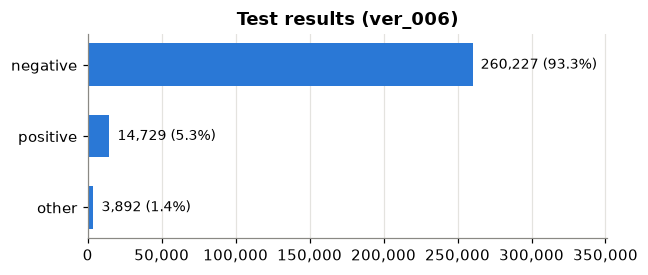

In [8]:
counts = df.corona_result.value_counts()
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(counts.index, counts.values, color=BLUE, height=0.6)
for y, v in enumerate(counts.values):
    ax.text(v, y, f"  {v:,} ({v / counts.sum():.1%})", va="center", fontsize=9)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(0, counts.max() * 1.35)
ax.set_title("Test results (ver_006)")
ax.grid(axis="y", visible=False)
plt.tight_layout()

The classes are **heavily imbalanced**: only ~5% of tests are positive. Accuracy alone will be misleading, which is why the paper reports auROC and auPRC.

## 6. Tests over time

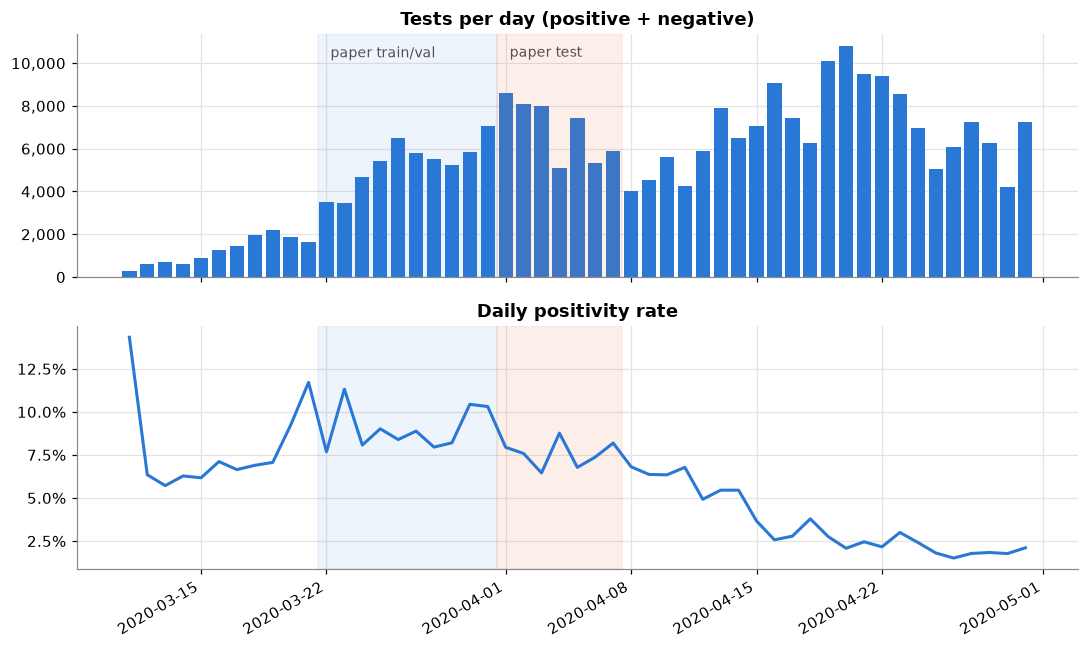

In [9]:
daily = (df[df.corona_result != "other"]
         .groupby("test_date")["corona_result"]
         .agg(tests="size", positives=lambda s: (s == "positive").sum()))
daily["positivity"] = daily.positives / daily.tests

TRAIN = (pd.Timestamp("2020-03-22"), pd.Timestamp("2020-03-31"))
TEST = (pd.Timestamp("2020-04-01"), pd.Timestamp("2020-04-07"))

# Two panels sharing the date axis (rather than one chart with two y-scales)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.bar(daily.index, daily.tests, color=BLUE, width=0.8)
ax1.set_title("Tests per day (positive + negative)")
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

ax2.plot(daily.index, daily.positivity, color=BLUE, linewidth=2)
ax2.set_title("Daily positivity rate")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

for ax in (ax1, ax2):
    ax.axvspan(TRAIN[0] - pd.Timedelta(hours=12), TRAIN[1] + pd.Timedelta(hours=12), color=BLUE, alpha=0.08)
    ax.axvspan(TEST[0] - pd.Timedelta(hours=12), TEST[1] + pd.Timedelta(hours=12), color=ORANGE, alpha=0.10)
ax1.text(TRAIN[0], ax1.get_ylim()[1] * 0.95, " paper train/val", color="#52514e", fontsize=9, va="top")
ax1.text(TEST[0], ax1.get_ylim()[1] * 0.95, " paper test", color="#52514e", fontsize=9, va="top")
fig.autofmt_xdate()
plt.tight_layout()

Testing ramps up sharply through March/April while positivity drops, as testing broadens beyond symptomatic/high-risk people. That shift in population is one reason the paper uses a **time-based** (prospective) split rather than a random one.

## 7. Reproduce the paper's train/test counts

Quick sanity check: filtering to the paper's date windows (and dropping `other` results) should give roughly 51,831 / 4,769 and 47,401 / 3,624.

In [10]:
def window(d, start, end):
    w = d[d.test_date.between(start, end) & (d.corona_result != "other")]
    return pd.Series({"individuals": len(w), "positive": (w.corona_result == "positive").sum()})

df_gender_known = df.dropna(subset=["gender"])

pd.DataFrame({
    "train/val (paper)": [51_831, 4_769],
    "train/val (all rows)": window(df, *TRAIN),
    "train/val (gender known)": window(df_gender_known, *TRAIN),
    "test (paper)": [47_401, 3_624],
    "test (all rows)": window(df, *TEST),
    "test (gender known)": window(df_gender_known, *TEST),
}).T

,individuals,positive
train/val (paper),51831,4769
train/val (all rows),53020,4795
train/val (gender known),51831,4769
test (paper),47401,3624
test (all rows),48462,3641
test (gender known),47401,3624


**Result:** using all rows gives ~2% too many. Dropping rows where `gender` is missing reproduces the paper's numbers **exactly**, so that's evidently the filtering the authors applied. (Rows with missing age were kept, so the model must have handled `NaN` for `Age_60`.)

## 8. Build the 8 binary features

Mapping the raw columns into the paper's feature names (matching the README's variable names). Missing values stay as `NaN` for now.

In [11]:
FEATURES = ["Cough", "Fever", "Sore_throat", "Shortness_of_breath", "Headache",
            "Age_60", "Male", "Contact_with_confirmed"]

def to_features(d: pd.DataFrame) -> pd.DataFrame:
    d = d[d.corona_result != "other"]
    return pd.DataFrame({
        "test_date": d.test_date,
        "Cough": d.cough,
        "Fever": d.fever,
        "Sore_throat": d.sore_throat,
        "Shortness_of_breath": d.shortness_of_breath,
        "Headache": d.head_ache,
        "Age_60": d.age_60_and_above.map({"Yes": 1, "No": 0}),
        "Male": d.gender.map({"male": 1, "female": 0}),
        "Contact_with_confirmed": (d.test_indication == "Contact with confirmed").astype(int),
        "positive": (d.corona_result == "positive").astype(int),
    })

feat = to_features(df)
feat.describe().T[["count", "mean"]].rename(columns={"mean": "share = 1"}).round(3)

,count,share = 1
test_date,274956,2020-04-10 12:12:04.933443
Cough,274704.0,0.15133
Fever,274704.0,0.077811
Sore_throat,274955.0,0.006881
Shortness_of_breath,274955.0,0.005634
Headache,274955.0,0.008667
Age_60,149292.0,0.170304
Male,255911.0,0.497712
Contact_with_confirmed,274956.0,0.038108
positive,274956.0,0.053569


## 9. How does each feature relate to a positive result?

For each feature, the positivity rate among people where it's **1** vs **0**. This is the single most useful picture for intuition about what the model will learn.

In [12]:
rows = []
for f in FEATURES:
    sub = feat.dropna(subset=[f])
    rows.append({
        "feature": f,
        "prevalence": sub[f].mean(),
        "positivity if 1": sub.loc[sub[f] == 1, "positive"].mean(),
        "positivity if 0": sub.loc[sub[f] == 0, "positive"].mean(),
    })
summary = pd.DataFrame(rows).set_index("feature")
summary["lift (1 vs 0)"] = summary["positivity if 1"] / summary["positivity if 0"]
summary = summary.sort_values("lift (1 vs 0)", ascending=False)
summary.style.format({"prevalence": "{:.1%}", "positivity if 1": "{:.1%}",
                      "positivity if 0": "{:.1%}", "lift (1 vs 0)": "{:.1f}x"})

,prevalence,positivity if 1,positivity if 0,lift (1 vs 0)
feature,,,,
Contact_with_confirmed,3.8%,69.8%,2.8%,24.9x
Headache,0.9%,93.8%,4.6%,20.5x
Sore_throat,0.7%,80.7%,4.8%,16.7x
Shortness_of_breath,0.6%,75.1%,5.0%,15.1x
Fever,7.8%,26.0%,3.6%,7.2x
Cough,15.1%,15.8%,3.5%,4.6x
Male,49.8%,5.9%,4.7%,1.3x
Age_60,17.0%,8.7%,7.5%,1.2x


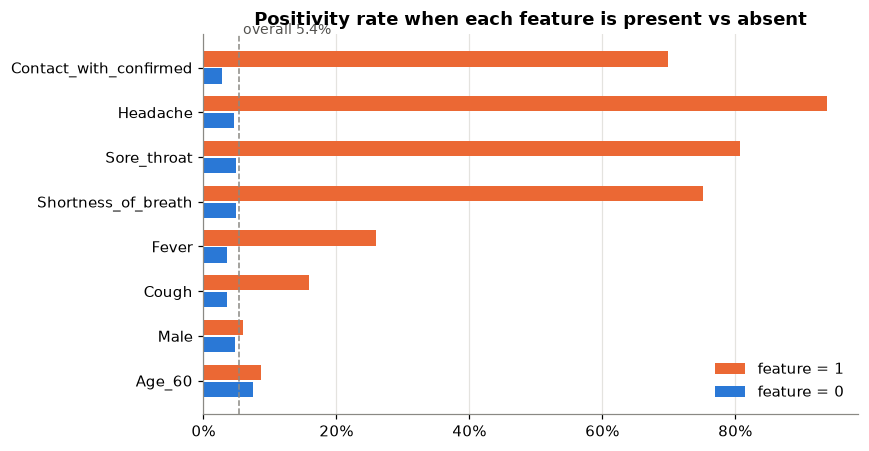

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.2))
y = range(len(summary))
h = 0.38
ax.barh([i - h / 2 for i in y], summary["positivity if 1"], height=h - 0.04, color=ORANGE, label="feature = 1")
ax.barh([i + h / 2 for i in y], summary["positivity if 0"], height=h - 0.04, color=BLUE, label="feature = 0")
ax.set_yticks(list(y), summary.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.axvline(feat.positive.mean(), color=GREY, linestyle="--", linewidth=1)
ax.text(feat.positive.mean(), -0.75, f" overall {feat.positive.mean():.1%}", color="#52514e", fontsize=9)
ax.set_title("Positivity rate when each feature is present vs absent")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()

Things to note:
- Contact with a confirmed case and fever are very strong signals. The paper's SHAP analysis found fever and cough most important, with contact also high.
- Symptoms are **rare** in the data (low prevalence), so most people tested have all-zero symptoms.
- The paper flags that symptom reporting was **biased**: symptoms were recorded more thoroughly for positive cases (via epidemiological follow-up). That likely inflates the lift for some symptoms. Their "balanced features" model drops the most biased ones.

## 10. Correlation between features

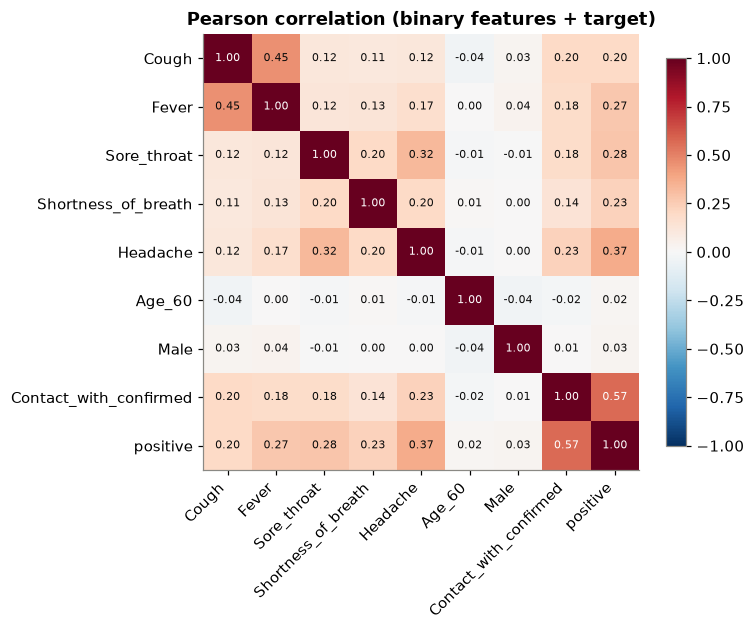

In [14]:
corr = feat[FEATURES + ["positive"]].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iat[i, j]) > 0.5 else "#0b0b0b")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Pearson correlation (binary features + target)")
plt.tight_layout()

## 11. Quick comparison with the November snapshot

The later dataset covers a much longer period. Does the relationship between features and positivity look the same?

In [15]:
feat_nov = to_features(df_nov)
compare = pd.DataFrame({
    "lift ver_006 (to 30 Apr)": summary["lift (1 vs 0)"],
    "lift ver_0083 (to 12 Nov)": [
        feat_nov.loc[feat_nov[f] == 1, "positive"].mean() / feat_nov.loc[feat_nov[f] == 0, "positive"].mean()
        for f in summary.index
    ],
})
compare.round(1)

,lift ver_006 (to 30 Apr),lift ver_0083 (to 12 Nov)
feature,,
Contact_with_confirmed,24.9,12.2
Headache,20.5,10.4
Sore_throat,16.7,9.2
Shortness_of_breath,15.1,8.7
Fever,7.2,8.1
Cough,4.6,5.6
Male,1.3,1.1
Age_60,1.2,0.9


## Part 1 summary

**What we've learned**
- ~279k rows in the paper's dataset; after dropping `other` results, ~5% positive, so heavily imbalanced.
- The paper's train/test counts are reproduced exactly by: date window + drop `other` results + drop missing `gender`.
- `age_60_and_above` is missing for ~46% of rows, and missingness differs sharply between positives and negatives (possible leakage). LightGBM can handle `NaN` natively.
- Contact with a confirmed case and fever are the strongest single signals; symptom features are sparse and possibly biased toward positives.

**Next steps** (picked up in Part 2)
1. Split by date exactly as the paper did (train/val 22–31 Mar, 4:1 split; test 1–7 Apr), dropping missing-gender rows.
2. Train LightGBM with the hyperparameters in `covidpred-master/hyperparameters.txt`.
3. Evaluate with auROC and auPRC (with bootstrap CIs), aiming for the paper's ~0.90 auROC.
4. Explain the model with SHAP; try the "balanced features" variant.

---
# Part 2: Reporting bias, PCA, the paper's SHAP plot, and reproducing the model

Questions from the team discussion:
1. **Reporting bias:** how does missing data differ between negative and positive cases? Where data is missing, is it typically one field or many?
2. **PCA:** are any of the features strongly correlated, and what do the principal components represent?
3. **SHAP:** the paper says male sex predicts a positive result, but Fig. 2 makes it look minor. What's going on?
4. **Reproduce the model** with the paper's split and hyperparameters.
5. **Gender:** does dropping the `Male` feature (and so keeping the ~2% of rows with unknown gender) help or hurt?

In [16]:
import lightgbm as lgb
import numpy as np
import shap
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SYMPTOMS = ["Cough", "Fever", "Sore_throat", "Shortness_of_breath", "Headache"]
OUTCOME = {0: "negative", 1: "positive"}

# The paper's date windows, *before* dropping missing gender, so we can see what was removed
paper_window = feat[feat.test_date.between(TRAIN[0], TEST[1])]

## 12. Missing data and reporting bias

The dataset can be "missing" information in two different ways:

- **Explicitly missing (`NaN`):** the field is blank (`None` in the CSV). This only really happens for `Age_60` and `Male`, plus a handful of `Cough`/`Fever` rows.
- **Silently missing:** a symptom recorded as `0` might mean "didn't have it" *or* "nobody asked/recorded it". This is the paper's bias concern: symptoms were followed up more thoroughly for people who tested positive, so a `0` is less trustworthy for negatives.

We look at both, for the full `ver_006` dataset and for the paper's window (22 Mar – 7 Apr).

### 12a. Explicitly missing values by outcome

In [17]:
def missing_by_outcome(d):
    m = d[FEATURES].isna().groupby(d.positive).mean().T * 100
    m.columns = [f"% missing ({OUTCOME[c]})" for c in m.columns]
    m["ratio (neg / pos)"] = m.iloc[:, 0] / m.iloc[:, 1]
    return m[m.iloc[:, :2].sum(axis=1) > 0]

print("Full ver_006 dataset")
display(missing_by_outcome(feat).round(2))
print("Paper window (22 Mar – 7 Apr)")
display(missing_by_outcome(paper_window).round(2))

Full ver_006 dataset


,% missing (negative),% missing (positive),ratio (neg / pos)
Cough,0.08,0.22,0.38
Fever,0.08,0.22,0.38
Sore_throat,0.00,0.01,0.00
Shortness_of_breath,0.00,0.01,0.00
Headache,0.00,0.01,0.00
Age_60,47.04,22.13,2.13
Male,6.87,7.94,0.87


Paper window (22 Mar – 7 Apr)


,% missing (negative),% missing (positive),ratio (neg / pos)
Cough,0.23,0.31,0.75
Fever,0.23,0.32,0.72
Male,2.37,0.51,4.65


- Over the **whole dataset**, age is missing about twice as often for negatives as for positives.
- In the **paper's window**, age is **never** missing, and missingness is low overall. Gender is the main gap, and it's missing ~4.7x more often for negatives (2.4% vs 0.5%). These are exactly the rows the paper dropped, so the paper's filter removed proportionally more negatives.

So the large age-missingness problem we spotted in Part 1 is entirely **after** the paper's window. It matters if we later train or test on later data, but not for reproducing the paper. The chart below shows when it starts.

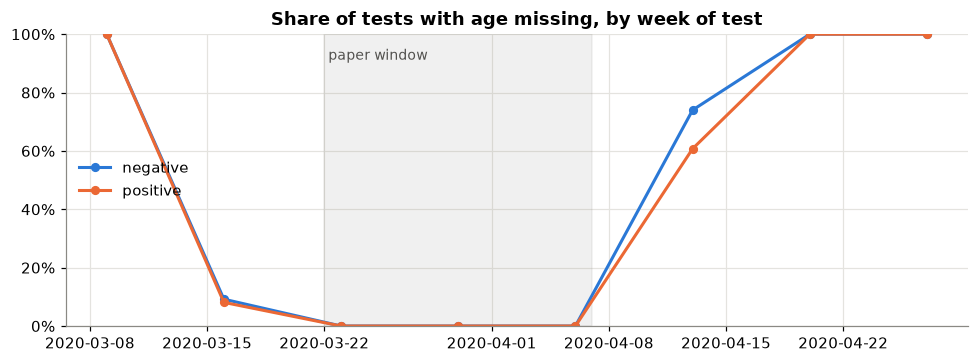

In [18]:
weekly = (feat.assign(age_missing=feat.Age_60.isna(), week=feat.test_date.dt.to_period("W").dt.start_time)
              .groupby(["week", "positive"]).age_missing.mean().unstack())

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(weekly.index, weekly[0], color=BLUE, linewidth=2, marker="o", markersize=5, label="negative")
ax.plot(weekly.index, weekly[1], color=ORANGE, linewidth=2, marker="o", markersize=5, label="positive")
ax.axvspan(TRAIN[0], TEST[1], color=GREY, alpha=0.12)
ax.text(TRAIN[0], 0.95, " paper window", color="#52514e", fontsize=9, va="top")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.set_title("Share of tests with age missing, by week of test")
ax.legend(frameon=False, loc="center left")
plt.tight_layout()

### 12b. When values are missing, how many are missing?

In [19]:
def n_missing_table(d):
    n = d[FEATURES].isna().sum(axis=1)
    t = pd.crosstab(n, d.positive.map(OUTCOME), normalize="columns").mul(100)
    t.index.name = "# features missing"
    return t

def missing_patterns(d):
    miss = d[FEATURES].isna()
    miss = miss[miss.any(axis=1)]
    pattern = miss.apply(lambda r: " + ".join(r.index[r]), axis=1)
    return pattern.groupby(d.positive.map(OUTCOME)).value_counts(normalize=True).mul(100).round(1).unstack(0).fillna(0)

for label, d in [("Full ver_006 dataset", feat), ("Paper window", paper_window)]:
    print(label, "- % of each outcome by number of missing features")
    display(n_missing_table(d).round(2))
print("Paper window - among rows with ANY missing value, which fields are missing (% of those rows)")
missing_patterns(paper_window)

Full ver_006 dataset - % of each outcome by number of missing features


positive,negative,positive
# features missing,,
0,48.29,72.14
1,49.34,25.26
2,2.36,2.55
3,0.00,0.03
4,0.00,0.01
7,0.00,0.01


Paper window - % of each outcome by number of missing features


positive,negative,positive
# features missing,,
0,97.40,99.16
1,2.37,0.55
2,0.23,0.30


Paper window - among rows with ANY missing value, which fields are missing (% of those rows)


positive,negative,positive
Cough,0.0,1.4
Cough + Fever,8.9,35.2
Fever,0.0,2.8
Male,91.1,60.6


Where data is missing it's almost always **one field**. Rows with 2+ missing fields are ~2–3% of the full dataset and <0.5% of the paper's window, similar for both classes. The five symptoms are (almost) never blank, so no row is "mostly missing".

- **Full dataset:** about half of negatives are missing one field (almost always age), against a quarter of positives.
- **Paper window:** negatives' missing rows are nearly all gender alone. For positives, over a third of the (few) missing rows are cough **and** fever together, a "symptoms not recorded" pattern rather than a demographics gap.

### 12c. Silent missingness: how many symptoms were reported?

positive,negative,positive
# symptoms reported,,
0,87.2,27.3
1,8.9,29.1
2,3.8,26.7
3,0.0,12.2
4,0.0,4.0
5,0.0,0.8


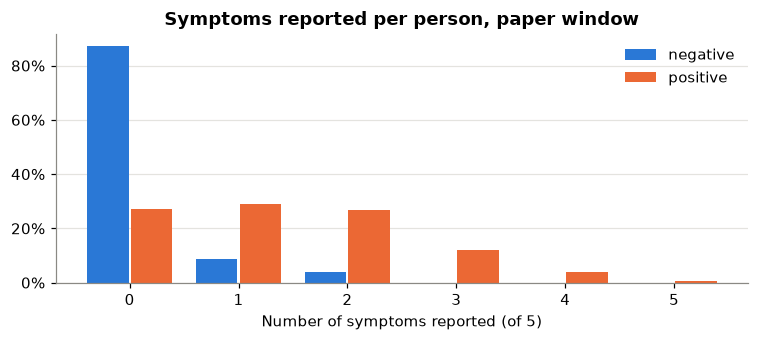

In [20]:
n_symptoms = paper_window[SYMPTOMS].sum(axis=1)
sym_table = pd.crosstab(n_symptoms.astype(int), paper_window.positive.map(OUTCOME), normalize="columns").mul(100)
sym_table.index.name = "# symptoms reported"
display(sym_table.round(1))

fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(sym_table))
ax.bar(x - 0.2, sym_table["negative"], width=0.38, color=BLUE, label="negative")
ax.bar(x + 0.2, sym_table["positive"], width=0.38, color=ORANGE, label="positive")
ax.set_xticks(x, sym_table.index)
ax.set_xlabel("Number of symptoms reported (of 5)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(100))
ax.set_title("Symptoms reported per person, paper window")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
plt.tight_layout()

Most negatives report **no symptoms at all**. A minority of positives also report none. We can't tell from the data whether an all-zero negative was genuinely symptom-free or just never followed up, and that's the core of the paper's bias concern.

### 12d. The paper's bias measure

The paper decides whether a symptom is "biased" using this question: *of everyone recorded as having the symptom, what share tested positive?* A symptom that is almost only ever recorded for positives is suspect. Recomputing it over the paper's window (gender known):

In [21]:
paper_rows = paper_window.dropna(subset=["Male"])
bias = pd.DataFrame({
    "% positive among those with symptom (ours)": [paper_rows.loc[paper_rows[s] == 1, "positive"].mean() * 100 for s in SYMPTOMS],
    "paper": [27.4, 45.9, 92.3, 92.4, 96.2],
}, index=SYMPTOMS).round(1)
bias["classed as"] = np.where(bias.paper > 90, "biased (dropped)", "balanced (kept)")
bias

,% positive among those with symptom (ours),paper,classed as
Cough,27.4,27.4,balanced (kept)
Fever,46.0,45.9,balanced (kept)
Sore_throat,92.4,92.3,biased (dropped)
Shortness_of_breath,92.1,92.4,biased (dropped)
Headache,96.3,96.2,biased (dropped)


These match the paper to within 0.1 percentage points. Headache, sore throat and shortness of breath are recorded almost only for positives, which is why the "balanced features" model drops them (section 18).

## 13. PCA: are any features strongly correlated?

PCA looks for directions (combinations of features) that capture the most variance. If a few features are strongly correlated, the first component or two will soak up a big share of the variance, and the loadings will show which features move together.

Notes:
- We use the paper's training window (gender known), dropping the few rows with missing age, and **standardise** each feature so the rare symptoms aren't swamped by common features like `Male`.
- The target (`positive`) is **not** included, since PCA is unsupervised. We overlay it afterwards to see whether the components separate outcomes.
- PCA is designed for continuous data. On binary features it still finds correlated groups fine, but don't read too much into the exact numbers. (Multiple Correspondence Analysis is the "proper" binary equivalent.)

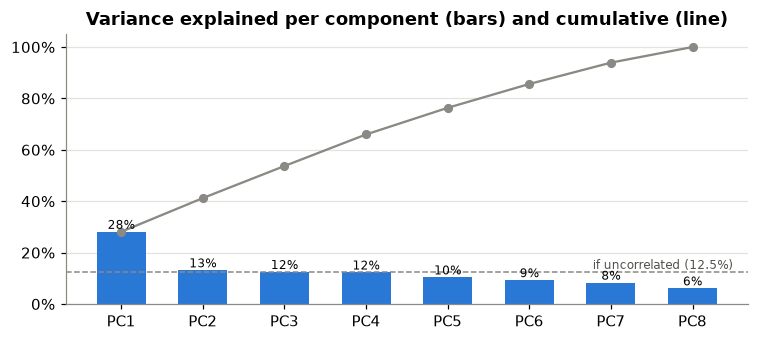

In [22]:
pca_data = feat[feat.test_date.between(*TRAIN)].dropna(subset=FEATURES)
Z = StandardScaler().fit_transform(pca_data[FEATURES])
pca = PCA().fit(Z)
pcs = pca.transform(Z)
pc_names = [f"PC{i + 1}" for i in range(len(FEATURES))]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(pc_names, pca.explained_variance_ratio_, color=BLUE, width=0.6)
ax.plot(pc_names, np.cumsum(pca.explained_variance_ratio_), color=GREY, marker="o", markersize=5, linewidth=1.5)
for i, (v, c) in enumerate(zip(pca.explained_variance_ratio_, np.cumsum(pca.explained_variance_ratio_))):
    ax.text(i, v, f"{v:.0%}", ha="center", va="bottom", fontsize=8)
ax.axhline(1 / len(FEATURES), color=GREY, linestyle="--", linewidth=1)
ax.text(len(FEATURES) - 0.5, 1 / len(FEATURES), "if uncorrelated (12.5%)", ha="right", va="bottom", fontsize=8, color="#52514e")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1.05)
ax.set_title("Variance explained per component (bars) and cumulative (line)")
ax.grid(axis="x", visible=False)
plt.tight_layout()

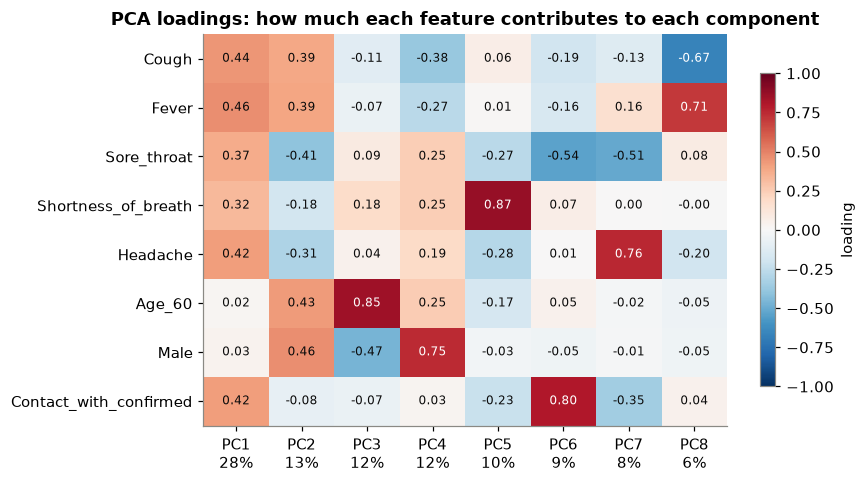

In [23]:
loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=pc_names)

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(loadings, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(pc_names)), [f"{n}\n{v:.0%}" for n, v in zip(pc_names, pca.explained_variance_ratio_)])
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(pc_names)):
        v = loadings.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.55 else "#0b0b0b")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="loading")
ax.set_title("PCA loadings: how much each feature contributes to each component")
plt.tight_layout()

In [24]:
# Do the components separate positives from negatives? Mean component score per outcome,
# plus the AUC you'd get using each component alone as a score (0.5 = no signal; <0.5 = signal with flipped sign)
sep = pd.DataFrame(pcs, columns=pc_names).groupby(pca_data.positive.map(OUTCOME).values).mean().T
sep["AUC of component alone"] = [roc_auc_score(pca_data.positive, pcs[:, i]) for i in range(len(pc_names))]
sep.round(3)

,negative,positive,AUC of component alone
PC1,-0.325,3.208,0.930
PC2,0.015,-0.148,0.513
PC3,-0.005,0.049,0.474
PC4,-0.025,0.246,0.556
PC5,0.020,-0.203,0.303
PC6,-0.053,0.523,0.514
PC7,0.005,-0.045,0.431
PC8,-0.019,0.189,0.604


**Reading the PCA**

- **No feature is redundant.** The strongest pairwise correlation is cough–fever at ~0.5 (moderate). Everything else is ≤0.33. After PC1, variance is spread almost evenly (PC2–PC8 are all close to the 12.5% "uncorrelated" line), so you'd need 6–7 components to keep 90% of the variance. PCA wouldn't usefully shrink this dataset.
- **PC1 (28%): "symptomatic / likely exposed".** All five symptoms *and* contact load positively, with age and sex ~0. It roughly counts how many risk flags someone has. It's the only component that strongly separates outcomes (AUC 0.93 in the training window).
- **PC2 (13%): "balanced vs biased symptoms".** Cough, fever, age and male push one way; sore throat, headache and shortness of breath push the other. This is the same split the paper drew in its bias analysis, found here without using the outcome at all. The "biased trio" tend to be recorded together, separately from cough/fever.
- **PC3 to PC8 each isolate roughly one feature** (PC3 age, PC4 sex, PC5 shortness of breath, PC6 contact, PC7 headache, PC8 cough-vs-fever). These are independent bits of information.

A notable result is that PC1 was fitted **without seeing the outcome**, yet it's almost as good a ranking as the full model. Applying it to the test week:

In [25]:
# Fit the scaler + PCA on the training window only, then score the test week with PC1
pca_test = feat[feat.test_date.between(*TEST)].dropna(subset=FEATURES)
scaler = StandardScaler().fit(pca_data[FEATURES])
pc1_test = PCA(n_components=1).fit(scaler.transform(pca_data[FEATURES])).transform(scaler.transform(pca_test[FEATURES]))[:, 0]
print(f"Test auROC using PC1 alone (unsupervised, no model): {roc_auc_score(pca_test.positive, pc1_test):.3f}")

Test auROC using PC1 alone (unsupervised, no model): 0.896


~0.90 from a single unsupervised component, roughly "how many symptoms + contact do you have". That tells us most of the predictive signal is just **"more flags = more likely positive"**. The LightGBM model's job is mostly weighting those flags, and there's little complex interaction for it to find.

## 14. Why does `Male` look minor in Fig. 2 but get called out as a predictor?

The repo ships the authors' trained model (`lgbm_model_all_features.txt`), so rather than guess, we can load it, recompute its SHAP values on the paper's test set, and redraw Fig. 2.

In [26]:
paper_test = feat[feat.test_date.between(*TEST)].dropna(subset=["Male"])
paper_trainval = feat[feat.test_date.between(*TRAIN)].dropna(subset=["Male"])

authors = lgb.Booster(model_file="covidpred-master/lgbm_model_all_features.txt")
print("Authors' feature order:", authors.feature_name())
print("Number of trees in the model:", authors.num_trees())

p_authors = authors.predict(paper_test[FEATURES].values)  # same order as FEATURES (Age_60 == 'Age_60+')
print(f"Test auROC of authors' model: {roc_auc_score(paper_test.positive, p_authors):.4f} (paper: 0.90)")
print(f"Range of predicted 'probabilities': {p_authors.min():.3f} to {p_authors.max():.3f}")

[LightGBM] [Warning] Ignoring unrecognized parameter 'max_conflict_rate' found in model string.
[LightGBM] [Warning] Ignoring unrecognized parameter 'sparse_threshold' found in model string.
[LightGBM] [Warning] Ignoring unrecognized parameter 'max_position' found in model string.
[LightGBM] [Warning] Ignoring unrecognized parameter 'lambdamart_norm' found in model string.
Authors' feature order: ['Cough', 'Fever', 'Sore_throat', 'Shortness_of_breath', 'Headache', 'Age_60+', 'Male', 'Contact_with_confirmed']
Number of trees in the model: 4
Test auROC of authors' model: 0.8988 (paper: 0.90)
Range of predicted 'probabilities': 0.136 to 0.320


Two things stand out before even looking at SHAP:

- The model is **only 4 trees**. With learning rate 0.05 and early stopping patience of 5, training stopped almost immediately (more on this in section 15).
- So its outputs barely move from the starting point: every prediction is between ~0.14 and ~0.32. It **ranks** people well (auROC 0.90), but the numbers aren't meaningful probabilities, even though the README describes the output as "the probability of being diagnosed".

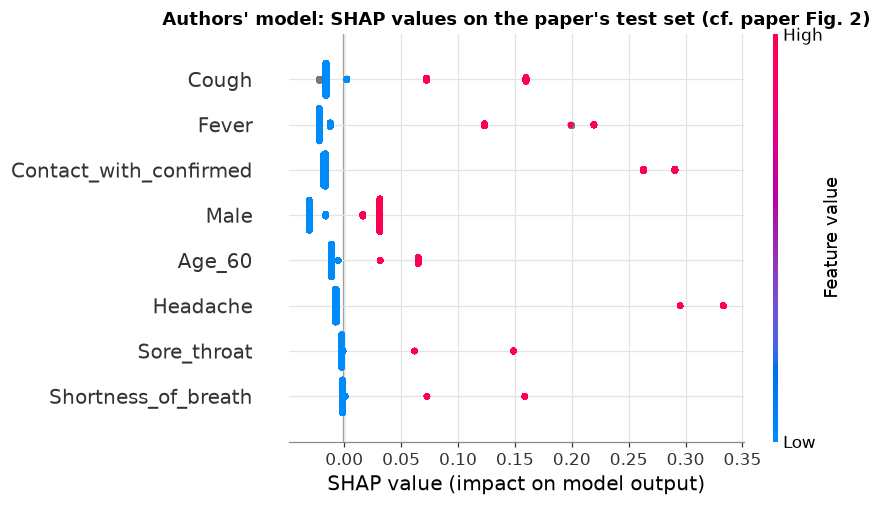

In [27]:
contrib = authors.predict(paper_test[FEATURES].values, pred_contrib=True)  # exact TreeSHAP, last column = base value
shap_authors = shap.Explanation(values=contrib[:, :-1], base_values=contrib[:, -1],
                                data=paper_test[FEATURES].values, feature_names=FEATURES)
shap.plots.beeswarm(shap_authors, show=False, color_bar=True)
plt.title("Authors' model: SHAP values on the paper's test set (cf. paper Fig. 2)")
plt.tight_layout()

That matches the paper's Fig. 2. Because every feature is binary, each feature only has **two possible SHAP values** (one for 0, one for 1), so the "beeswarm" collapses into two tight clusters per row. Each cluster is thousands of people stacked on one point, and the plot gives no visual sense of how many.

The table makes the picture much clearer:

In [28]:
def shap_table(expl, data):
    rows = {}
    for i, f in enumerate(expl.feature_names):
        v, x = expl.values[:, i], data[f].values
        rows[f] = {
            "% of people with feature = 1": np.mean(x == 1) * 100,
            "SHAP when = 1": v[x == 1].mean(),
            "SHAP when = 0": v[x == 0].mean(),
            "mean |SHAP| (plot ranking)": np.abs(v).mean(),
        }
    t = pd.DataFrame(rows).T
    t["effect per person (1 minus 0)"] = t["SHAP when = 1"] - t["SHAP when = 0"]
    return t.sort_values("mean |SHAP| (plot ranking)", ascending=False)

shap_table(shap_authors, paper_test).round(3)

,% of people with feature = 1,SHAP when = 1,SHAP when = 0,mean |SHAP| (plot ranking),effect per person (1 minus 0)
Cough,14.504,0.129,-0.016,0.032,0.145
Fever,7.251,0.152,-0.021,0.031,0.173
Contact_with_confirmed,5.224,0.277,-0.017,0.031,0.294
Male,51.805,0.031,-0.030,0.030,0.060
Age_60,16.076,0.065,-0.011,0.020,0.076
Headache,1.456,0.329,-0.008,0.012,0.336
Sore_throat,1.078,0.134,-0.002,0.004,0.137
Shortness_of_breath,0.690,0.136,-0.002,0.002,0.138


**This resolves the confusion.** The beeswarm orders features by **mean |SHAP|**, which mixes two different things:

> *mean |SHAP| ≈ how big the effect is per person × how many people it applies to*

- **`Male`** has a **small** per-person effect (about +0.03 for men, −0.03 for women, a swing of ~0.06 in log-odds). But *everyone* has a sex, and it's split ~50/50, so nearly every person gets a non-trivial push. That small-but-universal effect averages out comparable to cough and fever, and it ranks 4th.
- **`Headache`** has the **largest** per-person effect (+0.33), about **5–10x** bigger than `Male`. But only ~1% of people report it, so its mean |SHAP| is small and it ranks lower.

So both readings are right, about different questions:
- *"Does the model use sex?"* Yes, consistently: every male gets nudged up and every female down. That's what the paper means by "male sex was revealed as a predictor".
- *"Does sex matter much for an individual?"* No. Knowing someone is male shifts their risk far less than knowing they have a fever or a known contact.

Two more caveats worth raising in the discussion:
- **The SHAP scale is shrunk overall** because the model is only 4 trees, so compare features *relative to each other*, not by absolute size.
- **SHAP explains the model, not the world.** A male effect could be biological, or it could reflect *who got tested* (e.g. occupational exposure, testing policy). The raw data shows the same direction:

In [29]:
sex = paper_trainval.groupby("Male").positive.agg(["size", "mean"])
sex.index = ["female", "male"]
sex.columns = ["tested", "positivity"]
odds = sex.positivity / (1 - sex.positivity)
print(sex.assign(positivity=lambda t: (t.positivity * 100).round(2).astype(str) + "%"))
print(f"\nRaw odds ratio, male vs female: {odds['male'] / odds['female']:.2f}")

        tested positivity
female   26037      7.61%
male     25794     10.81%

Raw odds ratio, male vs female: 1.47


## 15. Reproduce the model

Following the paper's Methods:
- **Train/validation:** 22–31 March, gender known, split **4:1** (stratified on outcome).
- **Test:** 1–7 April, gender known.
- **LightGBM** with the hyperparameters from `hyperparameters.txt`: up to 603 rounds, early stopping after 5 rounds without improvement in validation auROC.
- Missing `Age_60` values stay as `NaN`, which LightGBM handles natively (the paper does the same).

In [30]:
PARAMS = {
    "objective": "binary",
    "metric": "auc",
    "num_leaves": 20,
    "min_data_in_leaf": 4,
    "feature_fraction": 0.2,
    "bagging_fraction": 0.8,
    "bagging_freq": 5,
    "learning_rate": 0.05,
    "verbose": -1,
}

def train_model(trainval, features, seed=0, patience=5, num_rounds=603):
    """Paper's procedure: 4:1 train/validation split, early stopping on validation auROC."""
    tr, va = train_test_split(trainval, test_size=0.2, random_state=seed, stratify=trainval.positive)
    return lgb.train(
        {**PARAMS, "seed": seed},
        lgb.Dataset(tr[features], tr.positive),
        num_boost_round=num_rounds,
        valid_sets=[lgb.Dataset(va[features], va.positive)],
        callbacks=[lgb.early_stopping(patience, verbose=False)],
    )

def predict(model, data, features):
    return model.predict(data[features], num_iteration=model.best_iteration)

model = train_model(paper_trainval, FEATURES, seed=0)
p_ours = predict(model, paper_test, FEATURES)
print(f"Stopped after {model.best_iteration} trees")
print(f"Test auROC: {roc_auc_score(paper_test.positive, p_ours):.4f}   auPRC: {average_precision_score(paper_test.positive, p_ours):.4f}")

Stopped after 22 trees
Test auROC: 0.8991   auPRC: 0.6391


### How stable is that? (it isn't, very)

The result depends on the random seed, which controls the train/validation split, bagging, and `feature_fraction`. With `feature_fraction=0.2` and only 8 features, **each tree only sees 1–2 features**. With so few trees, which features happen to get picked matters a lot. We retrain with 20 seeds and also try a more patient early-stopping setting.

In [31]:
SEEDS = range(20)
rows = []
for patience in [5, 50]:
    for s in SEEDS:
        m = train_model(paper_trainval, FEATURES, seed=s, patience=patience)
        p = predict(m, paper_test, FEATURES)
        rows.append({"patience": patience, "seed": s, "trees": m.best_iteration,
                     "auROC": roc_auc_score(paper_test.positive, p),
                     "auPRC": average_precision_score(paper_test.positive, p)})
stability = pd.DataFrame(rows)
stability.groupby("patience")[["trees", "auROC", "auPRC"]].agg(["mean", "std", "min", "max"]).round(4)

trees                      auROC                           auPRC  \
            mean       std min  max    mean     std     min     max    mean   
patience                                                                      
5          11.00    6.6728   4   29  0.8751  0.0416  0.7581  0.9020  0.6033   
50        216.25  212.7494   7  589  0.9011  0.0027  0.8937  0.9039  0.6742   

                                  
             std     min     max  
patience                          
5         0.0655  0.4376  0.6749  
50        0.0254  0.6200  0.7054

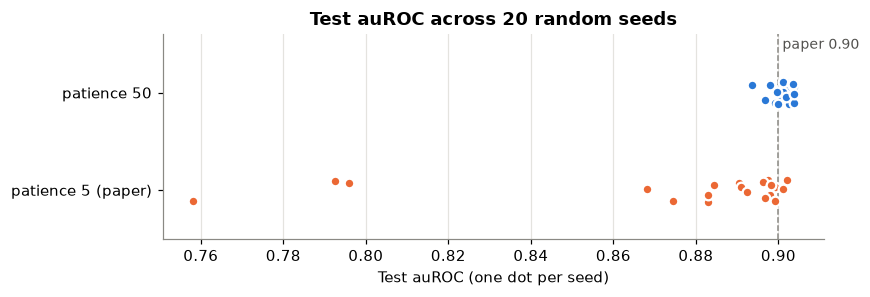

In [32]:
fig, ax = plt.subplots(figsize=(8, 2.8))
for y, (patience, color) in enumerate([(5, ORANGE), (50, BLUE)]):
    vals = stability.loc[stability.patience == patience, "auROC"]
    ax.scatter(vals, np.full(len(vals), y) + np.random.default_rng(0).uniform(-0.12, 0.12, len(vals)),
               s=40, color=color, edgecolor="white", linewidth=1.5, zorder=3)
ax.axvline(0.90, color=GREY, linestyle="--", linewidth=1)
ax.text(0.90, 1.45, " paper 0.90", color="#52514e", fontsize=9)
ax.set_yticks([0, 1], ["patience 5 (paper)", "patience 50"])
ax.set_ylim(-0.5, 1.6)
ax.set_xlabel("Test auROC (one dot per seed)")
ax.set_title("Test auROC across 20 random seeds")
ax.grid(axis="y", visible=False)
plt.tight_layout()

With the paper's settings (patience 5), training stops after 4–29 trees and test auROC ranges from **~0.76 to ~0.90** depending on the seed (mean ~0.875). A more patient early stopping (50 rounds) gives **0.901 ± 0.003** on every seed. The paper's 0.90 is reproducible, but the original setting needs a lucky seed. The authors' saved 4-tree model looks like one of the good draws.

**For the rest of the notebook we use patience = 50** as our "reproduced model". We report averages over seeds wherever we compare variants.

### Final model: performance with bootstrap confidence intervals

In [33]:
PATIENCE = 50
model = train_model(paper_trainval, FEATURES, seed=0, patience=PATIENCE)
p_ours = predict(model, paper_test, FEATURES)
y_test = paper_test.positive.values

def bootstrap_metrics(y, p, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    aucs, prcs = [], []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        aucs.append(roc_auc_score(y[idx], p[idx]))
        prcs.append(average_precision_score(y[idx], p[idx]))
    return np.percentile(aucs, [2.5, 97.5]), np.percentile(prcs, [2.5, 97.5])

results = {}
for name, p in [("ours", p_ours), ("authors' model", p_authors)]:
    auc_ci, prc_ci = bootstrap_metrics(y_test, p)
    results[name] = {
        "auROC": roc_auc_score(y_test, p), "auROC 95% CI": f"{auc_ci[0]:.3f}–{auc_ci[1]:.3f}",
        "auPRC": average_precision_score(y_test, p), "auPRC 95% CI": f"{prc_ci[0]:.3f}–{prc_ci[1]:.3f}",
    }
results["paper"] = {"auROC": 0.90, "auROC 95% CI": "0.892–0.905", "auPRC": np.nan, "auPRC 95% CI": ""}
pd.DataFrame(results).T.round(3)

,auROC,auROC 95% CI,auPRC,auPRC 95% CI
ours,0.90162,0.895–0.908,0.672776,0.657–0.689
authors' model,0.898763,0.892–0.905,0.650002,0.633–0.666
paper,0.9,0.892–0.905,NaN,


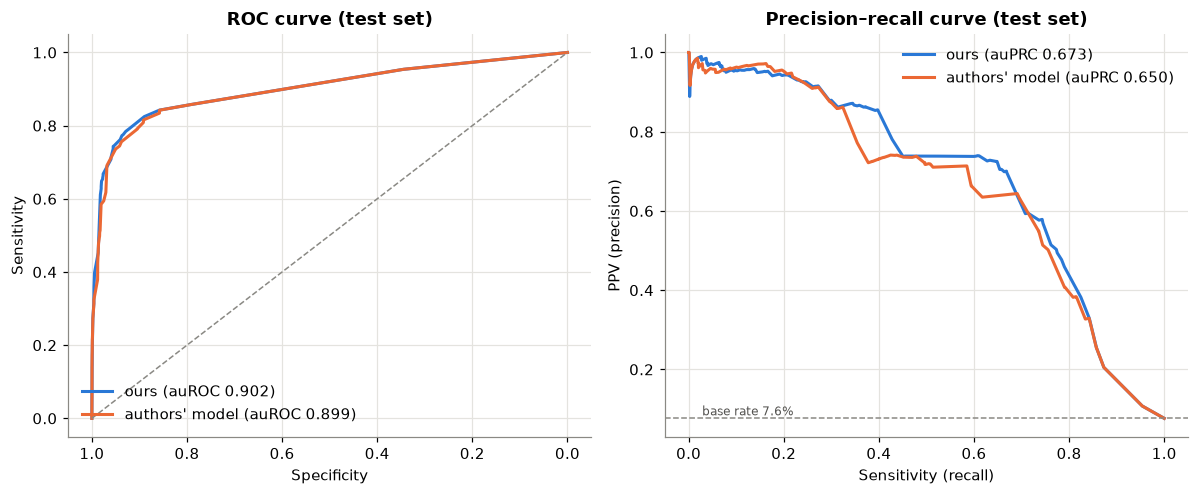

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))
for name, p, color in [("ours", p_ours, BLUE), ("authors' model", p_authors, ORANGE)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax1.plot(1 - fpr, tpr, color=color, linewidth=2, label=f"{name} (auROC {roc_auc_score(y_test, p):.3f})")
    ax2.plot(rec, prec, color=color, linewidth=2, label=f"{name} (auPRC {average_precision_score(y_test, p):.3f})")
ax1.plot([1, 0], [0, 1], color=GREY, linestyle="--", linewidth=1)
ax1.invert_xaxis()
ax1.set(xlabel="Specificity", ylabel="Sensitivity", title="ROC curve (test set)")
ax2.axhline(y_test.mean(), color=GREY, linestyle="--", linewidth=1)
ax2.text(0.02, y_test.mean(), f" base rate {y_test.mean():.1%}", va="bottom", fontsize=8, color="#52514e")
ax2.set(xlabel="Sensitivity (recall)", ylabel="PPV (precision)", title="Precision–recall curve (test set)")
for ax in (ax1, ax2):
    ax.legend(frameon=False, loc="lower left" if ax is ax1 else "upper right")
plt.tight_layout()

### Working points

With only 8 binary features there are at most 256 distinct inputs, so the model only produces a few dozen distinct scores and the ROC curve is a staircase. Each step is a possible threshold. The paper quotes two working points: **87.3% sensitivity / 72.0% specificity** and **85.8% / 79.2%**. Here are ours in the same region. The top two rows match the paper's working points **exactly**.

In [35]:
def working_points(y, p):
    rows = []
    np.seterr(invalid="ignore")  # PPV is undefined (0/0) at the highest threshold
    for t in np.unique(p):
        pred = p >= t
        tp, fp = (pred & (y == 1)).sum(), (pred & (y == 0)).sum()
        fn, tn = (~pred & (y == 1)).sum(), (~pred & (y == 0)).sum()
        rows.append({"threshold": t, "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
                     "PPV": tp / (tp + fp), "NPV": tn / (tn + fn), "% flagged": pred.mean()})
    return pd.DataFrame(rows)

wp = working_points(y_test, p_ours)
wp[wp.sensitivity.between(0.6, 0.95)].sort_values("sensitivity", ascending=False).style.format(
    {"threshold": "{:.3f}", **{c: "{:.1%}" for c in ["sensitivity", "specificity", "PPV", "NPV", "% flagged"]}}
).hide(axis="index")

threshold,sensitivity,specificity,PPV,NPV,% flagged
0.026,87.3%,72.0%,20.5%,98.6%,32.5%
0.036,85.8%,79.2%,25.4%,98.5%,25.8%
0.036,84.2%,85.8%,32.9%,98.5%,19.6%
0.047,82.5%,89.0%,38.2%,98.4%,16.5%
0.055,79.0%,92.3%,45.9%,98.2%,13.2%
0.075,78.4%,92.9%,47.7%,98.1%,12.6%
0.117,77.5%,93.4%,49.4%,98.0%,12.0%
0.169,77.3%,93.6%,50.1%,98.0%,11.8%
0.178,77.3%,93.7%,50.3%,98.0%,11.8%
0.190,76.2%,94.0%,51.4%,97.9%,11.3%


## 16. SHAP for our reproduced model

Same plot and table for our model. It has more trees, so its SHAP values are on a larger scale. The *relative* picture is what to compare with the authors' model.

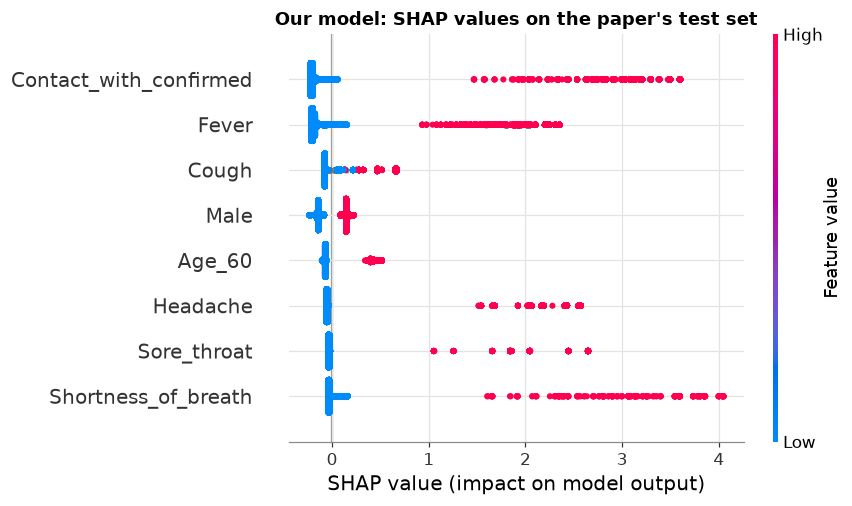

In [36]:
contrib = model.predict(paper_test[FEATURES], num_iteration=model.best_iteration, pred_contrib=True)
shap_ours = shap.Explanation(values=contrib[:, :-1], base_values=contrib[:, -1],
                             data=paper_test[FEATURES].values, feature_names=FEATURES)
shap.plots.beeswarm(shap_ours, show=False)
plt.title("Our model: SHAP values on the paper's test set")
plt.tight_layout()

In [37]:
shap_table(shap_ours, paper_test).round(3)

,% of people with feature = 1,SHAP when = 1,SHAP when = 0,mean |SHAP| (plot ranking),effect per person (1 minus 0)
Contact_with_confirmed,5.224,3.189,-0.212,0.367,3.400
Fever,7.251,1.907,-0.193,0.326,2.100
Cough,14.504,0.556,-0.066,0.145,0.623
Male,51.805,0.146,-0.144,0.145,0.290
Age_60,16.076,0.413,-0.072,0.127,0.486
Headache,1.456,2.221,-0.056,0.088,2.277
Sore_throat,1.078,2.121,-0.034,0.057,2.155
Shortness_of_breath,0.690,3.113,-0.028,0.052,3.141


The `Male` story holds here too: a consistent but small per-person effect, ranked by the plot as more important than rarer but much stronger symptoms. The grey points are people with **missing age**. LightGBM routes them down a learned branch, so "missing" itself gets a SHAP value.

## 17. Does dropping gender help or hurt?

The paper drops every row with unknown gender. If we don't use the `Male` feature at all, we can keep those rows. Four variants separate the two effects (*less data* vs *one fewer feature*):

| Variant | Training rows | Features |
|---|---|---|
| **A. Paper** | gender known | all 8 |
| **B. Keep all rows, Male as NaN** | all | all 8 (LightGBM handles missing `Male`) |
| **C. Drop the Male feature, keep all rows** | all | 7 (no `Male`) |
| **D. Drop the Male feature, paper rows** | gender known | 7 (no `Male`) |

Each is trained with 20 seeds and evaluated on two test sets: the paper's (gender known) and the full test week (including unknown gender). The full test week is the realistic case: a deployed screening tool would also meet people who don't give their sex.

In [38]:
trainval_all = feat[feat.test_date.between(*TRAIN)]
test_all = feat[feat.test_date.between(*TEST)]
NO_SEX = [f for f in FEATURES if f != "Male"]

variants = {
    "A. Paper (gender known, 8 features)": (paper_trainval, FEATURES),
    "B. All rows, Male as NaN (8 features)": (trainval_all, FEATURES),
    "C. All rows, no Male (7 features)": (trainval_all, NO_SEX),
    "D. Gender known, no Male (7 features)": (paper_trainval, NO_SEX),
}
test_sets = {"paper test (gender known)": paper_test, "full test week": test_all}

rows = []
for vname, (trainval, feats) in variants.items():
    for s in SEEDS:
        m = train_model(trainval, feats, seed=s, patience=PATIENCE)
        for tname, tdata in test_sets.items():
            rows.append({"variant": vname, "test set": tname, "seed": s, "train rows": len(trainval),
                         "auROC": roc_auc_score(tdata.positive, predict(m, tdata, feats))})
gender_exp = pd.DataFrame(rows)

summary_gender = gender_exp.groupby(["variant", "test set"]).auROC.agg(["mean", "std"]).unstack("test set")
summary_gender.insert(0, "train rows", gender_exp.groupby("variant")["train rows"].first())
summary_gender.round(4)

train rows           mean  \
test set                                         full test week   
variant                                                           
A. Paper (gender known, 8 features)        51831         0.8993   
B. All rows, Male as NaN (8 features)      53020         0.8993   
C. All rows, no Male (7 features)          53020         0.8911   
D. Gender known, no Male (7 features)      51831         0.8910   

                                                                 \
test set                              paper test (gender known)   
variant                                                           
A. Paper (gender known, 8 features)                      0.9011   
B. All rows, Male as NaN (8 features)                    0.9008   
C. All rows, no Male (7 features)                        0.8929   
D. Gender known, no Male (7 features)                    0.8928   

                                                 std                            
test set                              full test week paper test (gender known)  
variant                                                                         
A. Paper (gender known, 8 features)           0.0026                    0.0027  
B. All rows, Male as NaN (8 features)         0.0027                    0.0026  
C. All rows, no Male (7 features)             0.0035                    0.0035  
D. Gender known, no Male (7 features)         0.0035                    0.0035

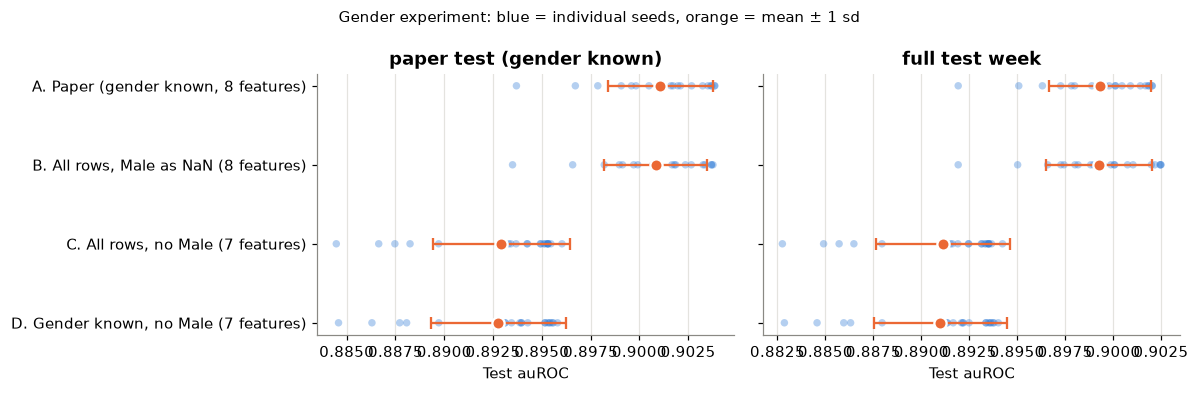

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
names = list(variants)
for ax, tname in zip(axes, test_sets):
    d = gender_exp[gender_exp["test set"] == tname]
    for y, v in enumerate(names):
        vals = d.loc[d.variant == v, "auROC"]
        ax.scatter(vals, np.full(len(vals), y), s=24, color=BLUE, alpha=0.35, edgecolor="none")
        ax.errorbar(vals.mean(), y, xerr=vals.std(), fmt="o", color=ORANGE, markersize=8,
                    markeredgecolor="white", markeredgewidth=1.5, capsize=4, zorder=3)
    ax.set_title(tname)
    ax.set_xlabel("Test auROC")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(names)), names)
axes[0].invert_yaxis()
fig.suptitle("Gender experiment: blue = individual seeds, orange = mean ± 1 sd", fontsize=10)
plt.tight_layout()

**Reading the results**
- **More data makes no difference** (A vs B, D vs C): identical auROC to 3 decimal places. The extra ~1,200 rows (2%) add nothing the model didn't already know.
- **Dropping the `Male` feature hurts** (A vs D, B vs C): about **−0.008 auROC**, roughly 3 standard deviations of the seed noise, and consistent on both test sets. It's small but real, matching the SHAP finding that sex carries a small but consistent signal.
- **Unknown sex at prediction time isn't a problem**: the paper's model (A) scores the full test week just as well as B, because LightGBM sends missing `Male` down a default branch.

**Verdict:** removing gender **hinders** the model slightly, and the extra data it frees up doesn't compensate. Keep the `Male` feature. Dropping vs keeping unknown-gender rows is a wash; keeping them (B) is slightly simpler, since nothing gets thrown away.

## 18. Balanced features only

The paper's bias-robust variant drops the three biased symptoms (headache, sore throat, shortness of breath) and reports **auROC 0.862**. The repo also ships this model (`lgbm_model_balanced_features.txt`).

In [40]:
BALANCED = ["Cough", "Fever", "Age_60", "Male", "Contact_with_confirmed"]
authors_bal = lgb.Booster(model_file="covidpred-master/lgbm_model_balanced_features.txt")
bal_aucs = [roc_auc_score(paper_test.positive, predict(train_model(paper_trainval, BALANCED, seed=s, patience=PATIENCE), paper_test, BALANCED))
            for s in SEEDS]
pd.DataFrame({
    "auROC": [0.862, roc_auc_score(paper_test.positive, authors_bal.predict(paper_test[BALANCED].values)),
              np.mean(bal_aucs), stability.query("patience == @PATIENCE").auROC.mean()],
}, index=["paper (balanced)", "authors' balanced model", f"ours balanced (mean of {len(SEEDS)} seeds)",
          f"ours all 8 features (mean of {len(SEEDS)} seeds)"]).round(4)

,auROC
paper (balanced),0.8620
authors' balanced model,0.8626
ours balanced (mean of 20 seeds),0.8714
ours all 8 features (mean of 20 seeds),0.9011


The authors' balanced model reproduces the paper's 0.862 exactly. Our retrained balanced model does slightly better (~0.87), likely due to the more patient early stopping. Either way, dropping the biased symptoms costs about 3–4 points of auROC. Some of the all-features model's performance comes from symptoms that may be recorded more for positives, so **~0.86 is probably the more honest estimate** of how this would perform where symptoms are collected evenly from everyone.

## Part 2 summary

| Question | Answer |
|---|---|
| Missing data by outcome | Whole dataset: age missing ~2x as often for negatives (47% vs 22%). Paper window: age never missing; gender missing ~4.7x more for negatives (these rows were dropped). Missing rows almost always lack a **single** field. The bigger bias is *silent*: 87% of negatives report zero symptoms vs 27% of positives, and the three "biased" symptoms are >90% positive. |
| PCA | No redundant features (strongest correlation: cough–fever ~0.5). PC1 = "number of risk flags" and alone gives ~0.90 test auROC with no model. PC2 rediscovers the paper's balanced-vs-biased symptom split. PCA isn't needed for modelling. |
| SHAP and sex | Fig. 2 ranks by **mean \|SHAP\|** = effect size × how many people it applies to. `Male` has a small effect that applies to everyone, so it ranks highly; headache has a big effect on few people. The paper's claim is "sex is used consistently", not "sex matters a lot". The authors' model is also only 4 trees, which compresses all SHAP values. |
| Reproduction | Test auROC 0.902 (95% CI 0.895–0.908) vs paper 0.90 (0.892–0.905), with the paper's working points matched exactly. The paper's early stopping (patience 5) is unstable: 0.76–0.90 across seeds. Patience 50 is reliably 0.90. |
| Drop gender? | Hurts slightly (−0.008 auROC); the extra 2% of rows add nothing. Keep `Male`. |
| Balanced features | Authors' model: 0.862 (matches paper); ours ~0.87. Likely the more realistic number. |

**Possible next steps:** test on later data (`ver_0083`) to see how the model ages as testing policy changes; probability calibration (the authors' outputs aren't real probabilities); the "missing age" leakage question for the later data; the paper's Fig. 4 simulation (randomly blanking negative symptom reports).

---
# Part 3: Handling the class imbalance

Only ~8% of the training window is positive (~11 negatives per positive). Common responses:

| Approach | What it does |
|---|---|
| **Class weights** (`scale_pos_weight` / `is_unbalance`) | Each positive counts as *w* negatives in the loss. No data is added or removed. |
| **Random undersampling** | Throw away negatives until the classes are 1:1. |
| **Random oversampling** | Duplicate positives until the classes are 1:1. |
| **SMOTE** (synthetic positives) | Interpolates between positives. **Not meaningful here**: every feature is binary, so interpolated values like `Fever = 0.4` are nonsense. With binary features, oversampling is just duplication, so it's effectively the same as class weighting. |
| **Threshold tuning** | Leave training alone and choose the decision threshold for the sensitivity/specificity trade-off you want. |

Rebalancing is applied to the **training split only**. The validation split (for early stopping) and the test set keep their real class balance, otherwise the scores would be flattering and unrealistic.

What to measure, since rebalancing affects different things:
- **auROC / auPRC:** how well the model *ranks* people. This is what the paper reports.
- **Brier score and mean predicted probability:** whether the outputs are believable *probabilities* (calibration).
- **Sensitivity / specificity at a 0.5 threshold:** what you'd get if you naively treated "probability > 50%" as positive.

In [41]:
def train_rebalanced(trainval, features, seed=0, method="none", patience=PATIENCE):
    tr, va = train_test_split(trainval, test_size=0.2, random_state=seed, stratify=trainval.positive)
    rng = np.random.default_rng(seed)
    params = {**PARAMS, "seed": seed}
    ratio = (tr.positive == 0).sum() / (tr.positive == 1).sum()

    if method == "weight (sqrt ratio)":
        params["scale_pos_weight"] = np.sqrt(ratio)
    elif method == "weight (full ratio)":
        params["scale_pos_weight"] = ratio  # equivalent to is_unbalance=True
    elif method == "undersample 1:1":
        pos, neg = tr[tr.positive == 1], tr[tr.positive == 0]
        tr = pd.concat([pos, neg.iloc[rng.choice(len(neg), len(pos), replace=False)]])
    elif method == "oversample 1:1":
        pos, neg = tr[tr.positive == 1], tr[tr.positive == 0]
        tr = pd.concat([neg, pos.iloc[rng.choice(len(pos), len(neg), replace=True)]])

    return lgb.train(params, lgb.Dataset(tr[features], tr.positive), num_boost_round=603,
                     valid_sets=[lgb.Dataset(va[features], va.positive)],
                     callbacks=[lgb.early_stopping(patience, verbose=False)])

METHODS = ["none", "weight (sqrt ratio)", "weight (full ratio)", "undersample 1:1", "oversample 1:1"]
train_ratio = (paper_trainval.positive == 0).sum() / paper_trainval.positive.sum()
print(f"Negatives per positive in training window: {train_ratio:.1f}")

rows, example_preds = [], {}
for method in METHODS:
    for s in SEEDS:
        m = train_rebalanced(paper_trainval, FEATURES, seed=s, method=method)
        p = predict(m, paper_test, FEATURES)
        pred = p >= 0.5
        rows.append({
            "method": method, "seed": s,
            "auROC": roc_auc_score(y_test, p),
            "auPRC": average_precision_score(y_test, p),
            "Brier": np.mean((p - y_test) ** 2),
            "mean predicted": p.mean(),
            "sens @0.5": pred[y_test == 1].mean(),
            "spec @0.5": (~pred[y_test == 0]).mean(),
        })
        if s == 0:
            example_preds[method] = p
imbalance = pd.DataFrame(rows)
print(f"Actual positive rate in test set: {y_test.mean():.3f}")
imbalance.groupby("method", sort=False).mean(numeric_only=True).drop(columns="seed").round(4)

Negatives per positive in training window: 9.9


Actual positive rate in test set: 0.076


,auROC,auPRC,Brier,mean predicted,sens @0.5,spec @0.5
method,,,,,,
none,0.9011,0.6742,0.0428,0.0826,0.3701,0.9924
weight (sqrt ratio),0.9016,0.6802,0.0453,0.1356,0.6177,0.9685
weight (full ratio),0.9019,0.6822,0.0746,0.2365,0.7579,0.9347
undersample 1:1,0.8997,0.6677,0.1002,0.2811,0.7638,0.9293
oversample 1:1,0.8993,0.6657,0.1002,0.2831,0.7619,0.9305


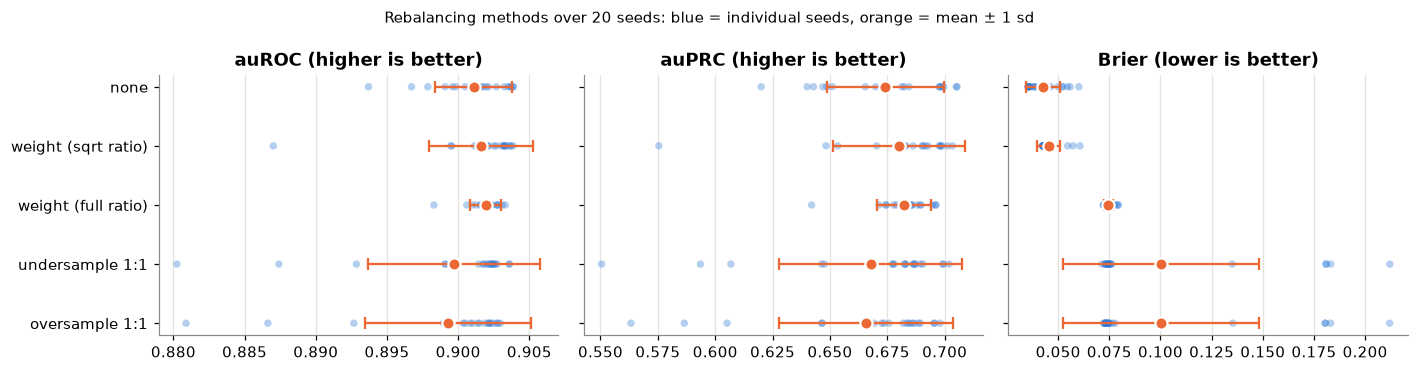

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, metric in zip(axes, ["auROC", "auPRC", "Brier"]):
    for y, method in enumerate(METHODS):
        vals = imbalance.loc[imbalance.method == method, metric]
        ax.scatter(vals, np.full(len(vals), y), s=24, color=BLUE, alpha=0.35, edgecolor="none")
        ax.errorbar(vals.mean(), y, xerr=vals.std(), fmt="o", color=ORANGE, markersize=8,
                    markeredgecolor="white", markeredgewidth=1.5, capsize=4, zorder=3)
    ax.set_title(metric + (" (lower is better)" if metric == "Brier" else " (higher is better)"))
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(METHODS)), METHODS)
axes[0].invert_yaxis()
fig.suptitle("Rebalancing methods over 20 seeds: blue = individual seeds, orange = mean ± 1 sd", fontsize=10)
plt.tight_layout()

### Calibration: do the predicted probabilities mean anything?

Group test-set predictions into bins and compare the average **predicted** probability with the **actual** positive rate in each bin. A well-calibrated model sits on the diagonal.

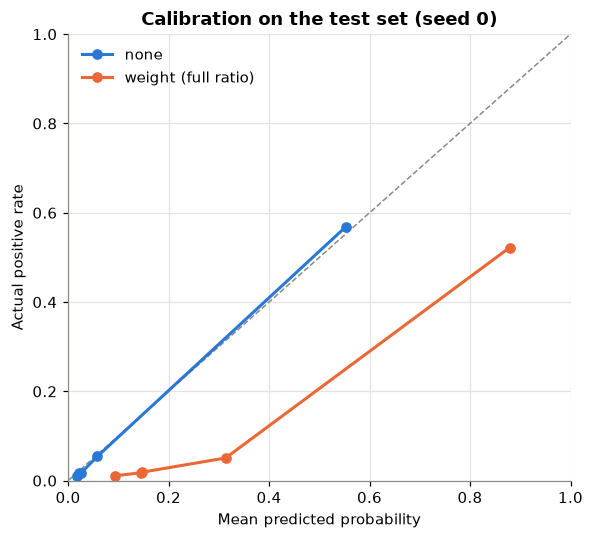

In [43]:
def calibration(y, p, bins=10):
    edges = np.unique(np.quantile(p, np.linspace(0, 1, bins + 1)))
    idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, len(edges) - 2)
    d = pd.DataFrame({"bin": idx, "p": p, "y": y}).groupby("bin").agg(predicted=("p", "mean"), actual=("y", "mean"), n=("y", "size"))
    return d

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1)
for method, color in [("none", BLUE), ("weight (full ratio)", ORANGE)]:
    c = calibration(y_test, example_preds[method])
    ax.plot(c.predicted, c.actual, color=color, linewidth=2, marker="o", markersize=6, label=method)
ax.set(xlabel="Mean predicted probability", ylabel="Actual positive rate", xlim=(0, 1), ylim=(0, 1),
       title="Calibration on the test set (seed 0)")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()

### Threshold tuning gets you the same operating points without retraining

Rebalancing mostly moves the scores up. The same sensitivity/specificity trade-off is available from the unweighted model by lowering the threshold. Below: for the weighted model's 0.5 threshold, find the unweighted model's threshold that gives the same sensitivity, and compare specificity.

In [44]:
p_base, p_weighted = example_preds["none"], example_preds["weight (full ratio)"]
target_sens = (p_weighted[y_test == 1] >= 0.5).mean()

wp_base = working_points(y_test, p_base)
match = wp_base.iloc[(wp_base.sensitivity - target_sens).abs().argmin()]
pd.DataFrame({
    "weighted model, threshold 0.5": {"threshold": 0.5, "sensitivity": target_sens,
                                      "specificity": (p_weighted[y_test == 0] < 0.5).mean()},
    "unweighted model, tuned threshold": match[["threshold", "sensitivity", "specificity"]].to_dict(),
}).T.style.format({"threshold": "{:.3f}", "sensitivity": "{:.1%}", "specificity": "{:.1%}"})

,threshold,sensitivity,specificity
"weighted model, threshold 0.5",0.500,78.1%,93.3%
"unweighted model, tuned threshold",0.075,78.4%,92.9%


## Part 3 summary: does rebalancing help?

**Ranking (auROC / auPRC): no meaningful change.** Every method lands at 0.899–0.902 auROC, well within seed-to-seed noise. Full-ratio class weighting is marginally best (+0.001 auROC, +0.008 auPRC). Its main benefit is that it's **more stable across seeds**: it removes most of the bad-seed outliers. Under- and oversampling are slightly worse and *less* stable. Undersampling also throws away ~90% of the negatives for no gain.

**Probabilities (Brier, mean predicted): rebalancing makes them worse.** The unweighted model's average prediction (8.3%) is close to the true positive rate (7.6%), and the calibration plot sits on the diagonal. Weighting or resampling tells the model positives are ~50% of the world, so it **inflates every probability** (mean prediction 24–28%). If we wanted honest "probability of COVID" outputs, as the README promises, rebalancing is the wrong move.

**The 0.5 threshold is where "imbalance" bites.** Unweighted at 0.5, the model catches only **37%** of positives (99% specificity), which looks like a classic imbalance failure. Rebalancing "fixes" it to ~76% sensitivity / ~93% specificity. But the last table shows the **unweighted model with its threshold lowered to ~0.075 gives the same trade-off** (78.4% / 92.9% vs 78.1% / 93.3%). The problem was the threshold, not the training.

**Recommendation**
- Keep training on the real class balance and **choose the threshold** for the screening goal (e.g. the paper's ~87% sensitivity working point). That keeps the probabilities meaningful.
- If you want the extra seed stability, use `scale_pos_weight` and then **recalibrate** the outputs (e.g. Platt scaling or isotonic regression on the validation set) before treating them as probabilities.
- Skip SMOTE (meaningless for binary features) and undersampling (discards data, no gain).

This matches the general rule: with a ranking metric like auROC and a model that already handles skew well (gradient boosting), rebalancing changes *where the scores sit*, not *how well they separate the classes*.